MLE analytique : 0.7089999914169312
theta estimé = 0.7090 | vrai = 0.7 | MLE = 0.7090


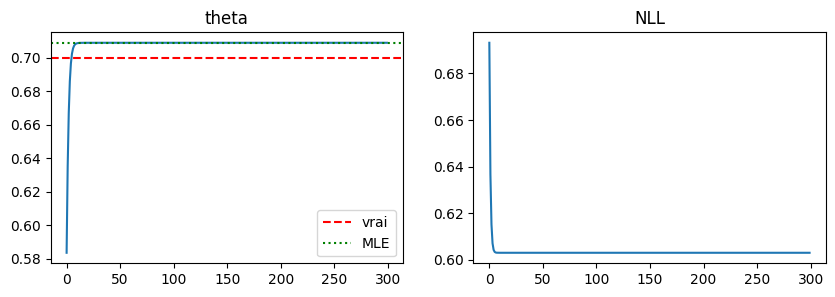

theta (sigmoïde) = 0.7090


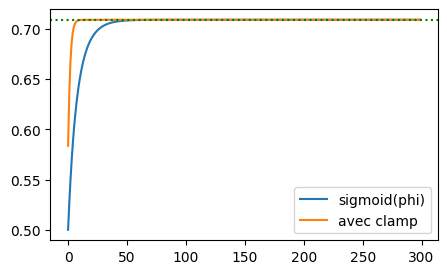

mu = 1.991 (vrai 2.0) | sigma = 1.445 (vrai 1.5)
Empirique : mean = 1.991, std = 1.445


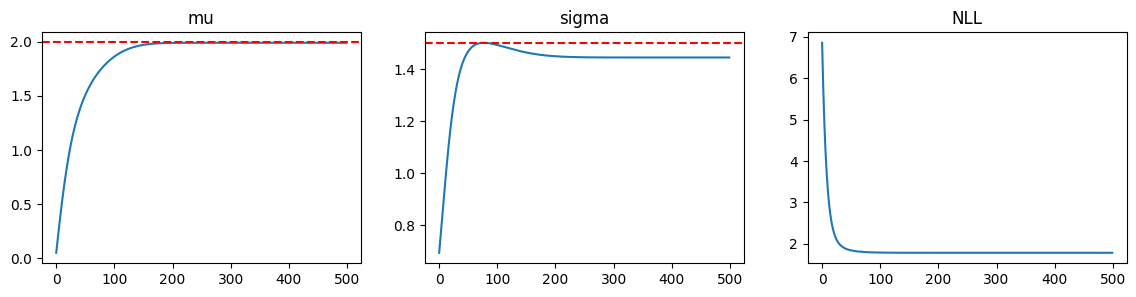

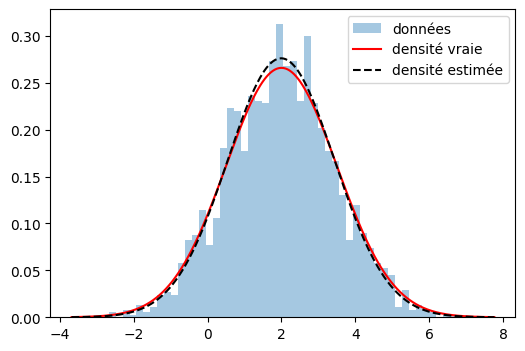

mu estimé : [ 1.0217671 -1.9471222  0.490365 ] | vrai : [ 1.  -2.   0.5]
Sigma estimée :
 [[ 1.031867    0.7888963   0.24483968]
 [ 0.7888963   1.7545185  -0.297345  ]
 [ 0.24483968 -0.297345    0.91425824]] 
Sigma vraie :
 [[ 1.1   0.8   0.3 ]
 [ 0.8   1.74 -0.26]
 [ 0.3  -0.26  0.93]]


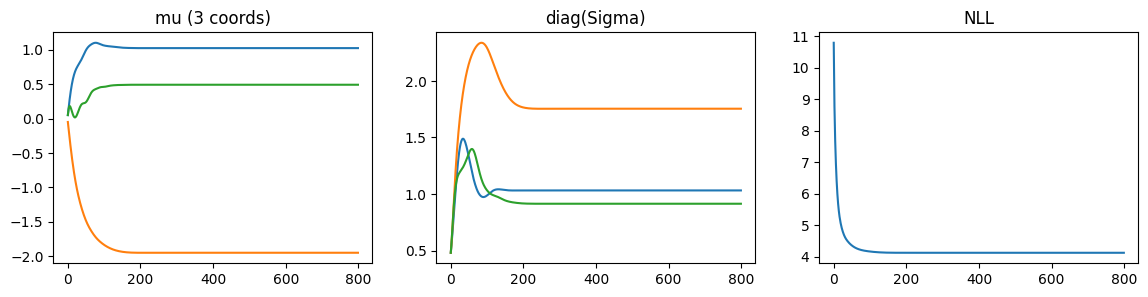

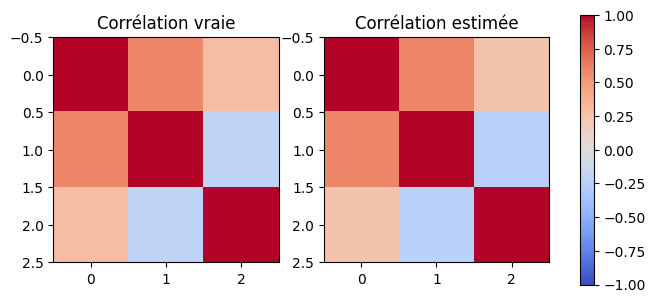

Convergence en 200 itérations


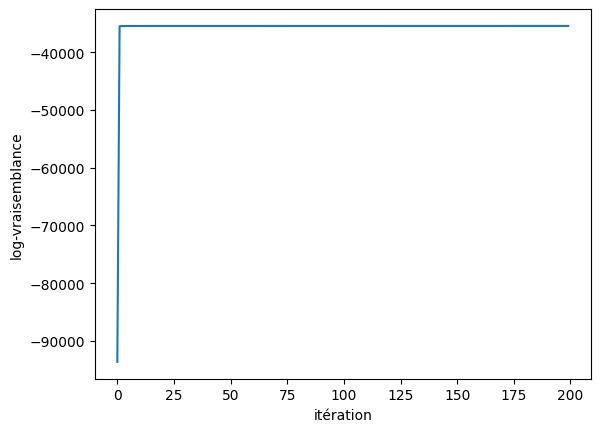


Composante vraie 0 <-> estimée 2
 pi    : 0.3 -> 0.066
 mu    : [0. 0. 0.] -> [-3.92  3.74  5.1 ]
 |dSig|: 1.103

Composante vraie 1 <-> estimée 0
 pi    : 0.5 -> 0.801
 mu    : [5. 5. 0.] -> [ 3.1   3.08 -0.01]
 |dSig|: 11.36

Composante vraie 2 <-> estimée 1
 pi    : 0.2 -> 0.134
 mu    : [-4.  4.  5.] -> [-4.06  4.21  4.92]
 |dSig|: 0.323


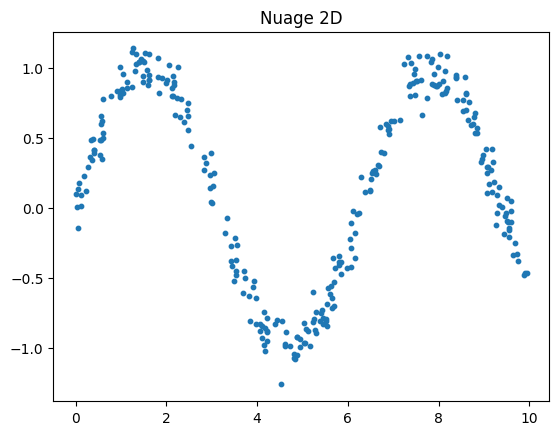

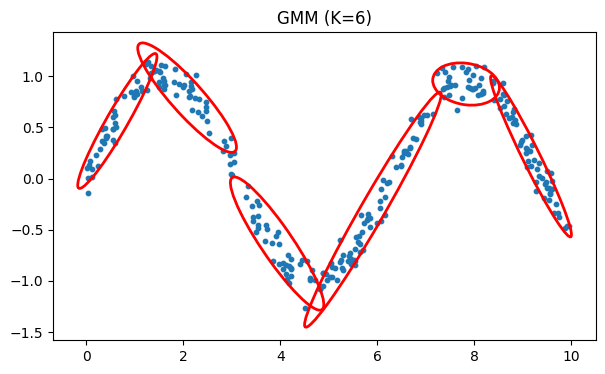

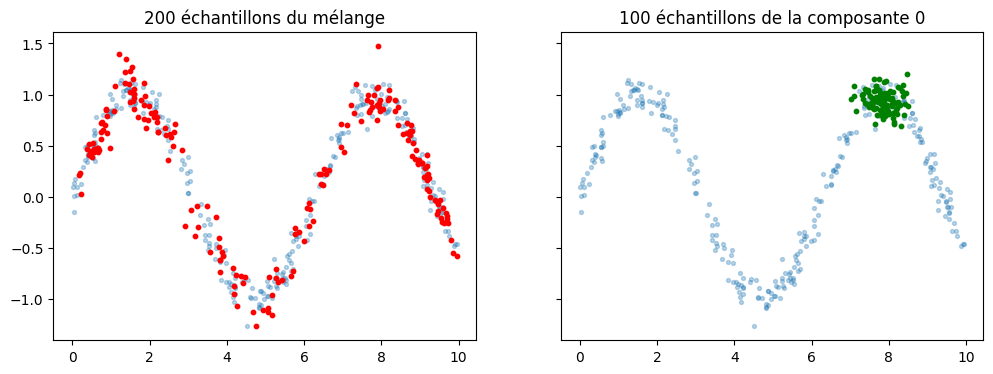

In [1]:
# TP Modèles génératifs - Partie 1 : estimation de distributions
# Chaque bloc "# %%" = une cellule de notebook

# %% Imports
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal, norm
from scipy.optimize import linear_sum_assignment
from matplotlib.patches import Ellipse
from sklearn.mixture import GaussianMixture

np.random.seed(0)
torch.manual_seed(0)

# =====================================================================
# 1.1 BERNOULLI
# =====================================================================
# %% Données
true_p = 0.7
N = 1000
x = torch.tensor((np.random.rand(N) < true_p).astype(np.float32))
theta_mle = x.mean().item()
print("MLE analytique :", theta_mle)

# %% Descente de gradient sur theta (avec clamp manuel)
def nll_bernoulli(theta, x):
    return -(x * torch.log(theta) + (1 - x) * torch.log(1 - theta)).mean()

theta = torch.tensor(0.5, requires_grad=True)
opt = torch.optim.SGD([theta], lr=0.1)
hist_theta, hist_nll = [], []
for it in range(300):
    opt.zero_grad()
    loss = nll_bernoulli(theta, x)
    loss.backward()
    opt.step()
    with torch.no_grad():
        theta.clamp_(1e-4, 1 - 1e-4)   # clamp manuel
    hist_theta.append(theta.item())
    hist_nll.append(loss.item())

print(f"theta estimé = {theta.item():.4f} | vrai = {true_p} | MLE = {theta_mle:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(hist_theta); ax[0].axhline(true_p, color='r', ls='--', label='vrai')
ax[0].axhline(theta_mle, color='g', ls=':', label='MLE'); ax[0].set_title("theta"); ax[0].legend()
ax[1].plot(hist_nll); ax[1].set_title("NLL")
plt.show()

# %% Reparamétrisation theta = sigmoid(phi) (pas de clamp)
phi = torch.tensor(0.0, requires_grad=True)
opt = torch.optim.SGD([phi], lr=0.5)
hist_theta2, hist_nll2 = [], []
for it in range(300):
    opt.zero_grad()
    th = torch.sigmoid(phi)
    loss = nll_bernoulli(th, x)
    loss.backward()
    opt.step()
    hist_theta2.append(th.item())
    hist_nll2.append(loss.item())

print(f"theta (sigmoïde) = {torch.sigmoid(phi).item():.4f}")
plt.figure(figsize=(5, 3))
plt.plot(hist_theta2, label="sigmoid(phi)")
plt.plot(hist_theta, label="avec clamp")
plt.axhline(theta_mle, color='g', ls=':'); plt.legend(); plt.show()

# =====================================================================
# 1.2 GAUSSIENNE UNIVARIÉE
# =====================================================================
# %% Données
mu_true, sigma_true = 2.0, 1.5
N = 2000
x = torch.tensor(np.random.normal(mu_true, sigma_true, N), dtype=torch.float32)

# %% NLL + optimisation
def nll_gauss(x, mu, sigma):
    return (torch.log(sigma) + 0.5 * np.log(2 * np.pi)
            + (x - mu) ** 2 / (2 * sigma ** 2)).mean()

mu = torch.tensor(0.0, requires_grad=True)
rho = torch.tensor(0.0, requires_grad=True)
opt = torch.optim.Adam([mu, rho], lr=0.05)
h_mu, h_sig, h_nll = [], [], []
for it in range(500):
    opt.zero_grad()
    sigma = F.softplus(rho) + 1e-6
    loss = nll_gauss(x, mu, sigma)
    loss.backward()
    opt.step()
    h_mu.append(mu.item()); h_sig.append(sigma.item()); h_nll.append(loss.item())

sigma_hat = (F.softplus(rho) + 1e-6).item()
print(f"mu = {mu.item():.3f} (vrai {mu_true}) | sigma = {sigma_hat:.3f} (vrai {sigma_true})")
print(f"Empirique : mean = {x.mean():.3f}, std = {x.std(unbiased=False):.3f}")

# %% Courbes de convergence + densités
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
ax[0].plot(h_mu); ax[0].axhline(mu_true, color='r', ls='--'); ax[0].set_title("mu")
ax[1].plot(h_sig); ax[1].axhline(sigma_true, color='r', ls='--'); ax[1].set_title("sigma")
ax[2].plot(h_nll); ax[2].set_title("NLL")
plt.show()

grid = np.linspace(x.min().item() - 1, x.max().item() + 1, 400)
plt.figure(figsize=(6, 4))
plt.hist(x.numpy(), bins=50, density=True, alpha=0.4, label="données")
plt.plot(grid, norm.pdf(grid, mu_true, sigma_true), 'r', label="densité vraie")
plt.plot(grid, norm.pdf(grid, mu.item(), sigma_hat), 'k--', label="densité estimée")
plt.legend(); plt.show()

# =====================================================================
# 1.2 GAUSSIENNE MULTIVARIÉE (d=3), Sigma = L L^T
# =====================================================================
# %% Données
d = 3
mu_true_m = np.array([1.0, -2.0, 0.5])
A = np.array([[1.0, 0.0, 0.0], [0.8, 1.0, 0.0], [0.3, -0.5, 0.7]])
Sigma_true = A @ A.T + 0.1 * np.eye(d)
N = 2000
X = torch.tensor(np.random.multivariate_normal(mu_true_m, Sigma_true, N), dtype=torch.float32)

# %% Paramétrisation + NLL
def build_L(L_raw):
    """Triangulaire inférieure, diagonale positive (softplus)."""
    return torch.tril(L_raw, -1) + torch.diag(F.softplus(torch.diagonal(L_raw)) + 1e-4)

def nll_mvn(X, mu, L):
    diff = (X - mu).T                                    # (d, N)
    z = torch.linalg.solve_triangular(L, diff, upper=False)
    maha = (z ** 2).sum(0)                               # (x-mu)^T Sigma^-1 (x-mu)
    logdet = 2 * torch.log(torch.diagonal(L)).sum()      # log|Sigma|
    return (0.5 * d * np.log(2 * np.pi) + 0.5 * logdet + 0.5 * maha).mean()

mu_p = torch.zeros(d, requires_grad=True)
L_raw = torch.zeros(d, d, requires_grad=True)
opt = torch.optim.Adam([mu_p, L_raw], lr=0.05)
h_mu, h_diag, h_nll = [], [], []
for it in range(800):
    opt.zero_grad()
    L = build_L(L_raw)
    loss = nll_mvn(X, mu_p, L)
    loss.backward()
    opt.step()
    Sig = (L @ L.T).detach()
    h_mu.append(mu_p.detach().numpy().copy())
    h_diag.append(torch.diagonal(Sig).numpy().copy())
    h_nll.append(loss.item())

L = build_L(L_raw).detach()
Sigma_hat = (L @ L.T).numpy()
print("mu estimé :", mu_p.detach().numpy(), "| vrai :", mu_true_m)
print("Sigma estimée :\n", Sigma_hat, "\nSigma vraie :\n", Sigma_true)

# %% Convergence
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
ax[0].plot(np.array(h_mu)); ax[0].set_title("mu (3 coords)")
ax[1].plot(np.array(h_diag)); ax[1].set_title("diag(Sigma)")
ax[2].plot(h_nll); ax[2].set_title("NLL")
plt.show()

# %% Heatmaps des corrélations
def corr(S):
    s = np.sqrt(np.diag(S)); return S / np.outer(s, s)

fig, ax = plt.subplots(1, 2, figsize=(8, 3.5))
for a, S, t in zip(ax, [Sigma_true, Sigma_hat], ["Corrélation vraie", "Corrélation estimée"]):
    im = a.imshow(corr(S), vmin=-1, vmax=1, cmap='coolwarm'); a.set_title(t)
plt.colorbar(im, ax=ax); plt.show()

# =====================================================================
# 1.3 GMM + EM (K=3, d=3, N=6000)
# =====================================================================
# %% Données synthétiques
K, d, N = 3, 3, 6000
pi_true = np.array([0.3, 0.5, 0.2])
mus_true = np.array([[0, 0, 0], [5, 5, 0], [-4, 4, 5]], dtype=float)
Sigmas_true = np.array([np.eye(d) * 1.0,
                        [[2, 0.5, 0], [0.5, 1, 0], [0, 0, 1.5]],
                        [[1, -0.3, 0.2], [-0.3, 1.5, 0], [0.2, 0, 1]]])
z = np.random.choice(K, size=N, p=pi_true)
X = np.array([np.random.multivariate_normal(mus_true[k], Sigmas_true[k]) for k in z])

# %% Algorithme EM
def log_lik(X, pi, mus, Sigmas):
    dens = np.column_stack([pi[k] * multivariate_normal.pdf(X, mus[k], Sigmas[k]) for k in range(len(pi))])
    return np.log(dens.sum(1)).sum(), dens

def em_gmm(X, K, max_iter=200, tol=1e-6, reg=1e-6):
    N, d = X.shape
    pi = np.ones(K) / K
    mus = X[np.random.choice(N, K, replace=False)]
    Sigmas = np.array([np.eye(d) for _ in range(K)])
    ll_hist = []
    for it in range(max_iter):
        # E-step
        ll, dens = log_lik(X, pi, mus, Sigmas)
        r = dens / dens.sum(1, keepdims=True)
        # M-step
        Nk = r.sum(0)
        pi = Nk / N
        mus = (r.T @ X) / Nk[:, None]
        for k in range(K):
            diff = X - mus[k]
            Sigmas[k] = (r[:, k, None] * diff).T @ diff / Nk[k] + reg * np.eye(d)
        ll_hist.append(ll)
        if it > 0 and abs(ll_hist[-1] - ll_hist[-2]) < tol:
            break
    return pi, mus, Sigmas, ll_hist

pi_hat, mus_hat, Sigmas_hat, ll_hist = em_gmm(X, K)
print(f"Convergence en {len(ll_hist)} itérations")
plt.plot(ll_hist); plt.xlabel("itération"); plt.ylabel("log-vraisemblance"); plt.show()

# %% Alignement (label switching) + comparaison
cost = np.linalg.norm(mus_hat[:, None, :] - mus_true[None, :, :], axis=2)  # (estimé, vrai)
row, col = linear_sum_assignment(cost)
perm = np.empty(K, dtype=int)
perm[col] = row            # perm[k_vrai] = k_estimé

for k in range(K):
    j = perm[k]
    print(f"\nComposante vraie {k} <-> estimée {j}")
    print(" pi    :", pi_true[k], "->", round(pi_hat[j], 3))
    print(" mu    :", mus_true[k], "->", np.round(mus_hat[j], 2))
    print(" |dSig|:", np.linalg.norm(Sigmas_true[k] - Sigmas_hat[j]).round(3))

# =====================================================================
# 1.4 GMM SUR NUAGE 2D
# =====================================================================
# %% Données
n_samples = 300
x1 = np.random.uniform(0, 10, n_samples)
x2 = np.sin(x1) + np.random.normal(0, 0.1, n_samples)
X2 = np.c_[x1, x2]
plt.scatter(X2[:, 0], X2[:, 1], s=10); plt.title("Nuage 2D"); plt.show()

# %% Ajustement + ellipses
gmm = GaussianMixture(n_components=6, random_state=0).fit(X2)

def plot_ellipses(gmm, ax, n_std=2, color='r'):
    for mean, cov in zip(gmm.means_, gmm.covariances_):
        vals, vecs = np.linalg.eigh(cov)
        order = vals.argsort()[::-1]
        vals, vecs = vals[order], vecs[:, order]
        angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
        w, h = 2 * n_std * np.sqrt(vals)
        ax.add_patch(Ellipse(mean, w, h, angle=angle, fill=False, color=color, lw=2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X2[:, 0], X2[:, 1], s=10)
plot_ellipses(gmm, ax)
ax.set_title("GMM (K=6)"); plt.show()

# %% Génération globale vs conditionnée à une composante
S_glob, _ = gmm.sample(200)
i = 0
S_comp = np.random.multivariate_normal(gmm.means_[i], gmm.covariances_[i], 100)

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax[0].scatter(X2[:, 0], X2[:, 1], s=8, alpha=0.3)
ax[0].scatter(S_glob[:, 0], S_glob[:, 1], s=10, c='r'); ax[0].set_title("200 échantillons du mélange")
ax[1].scatter(X2[:, 0], X2[:, 1], s=8, alpha=0.3)
ax[1].scatter(S_comp[:, 0], S_comp[:, 1], s=10, c='g'); ax[1].set_title(f"100 échantillons de la composante {i}")
plt.show()

X : (5000, 784)


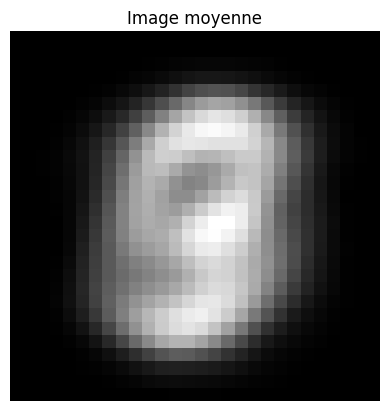

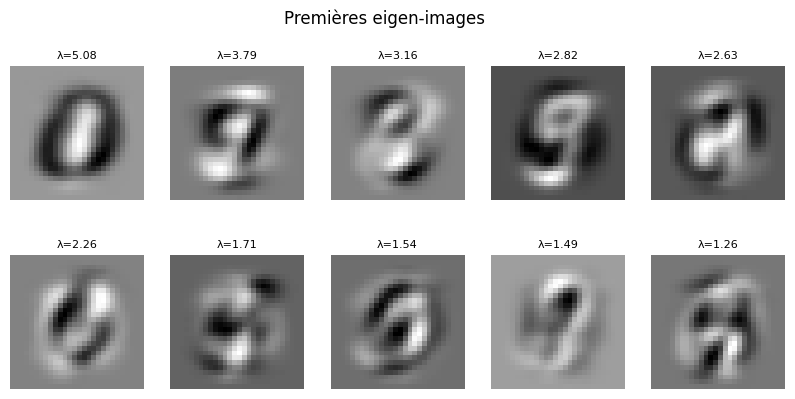

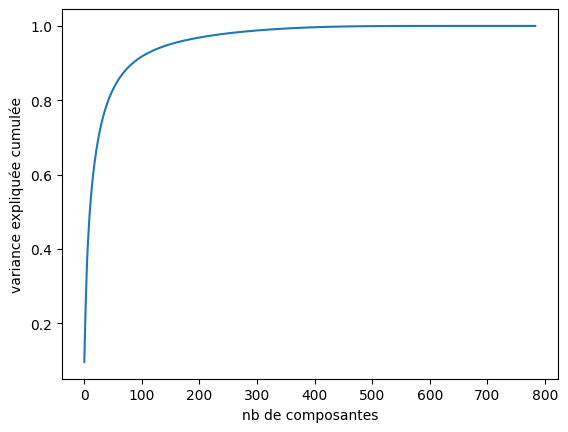

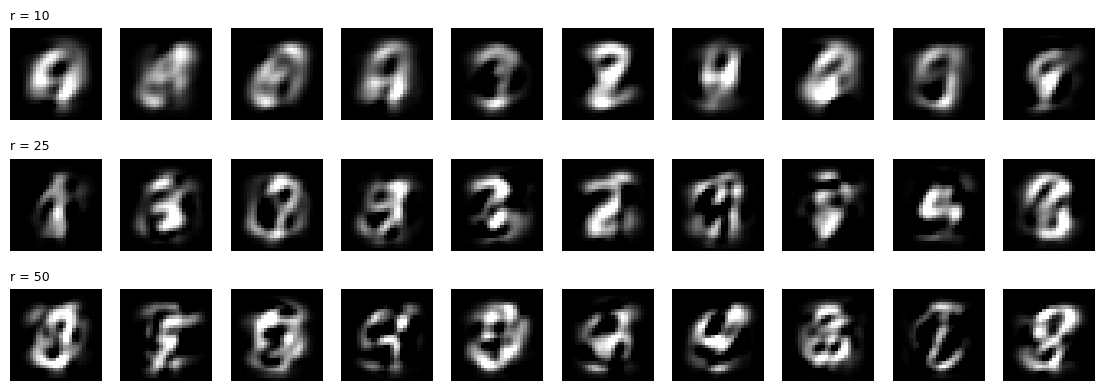

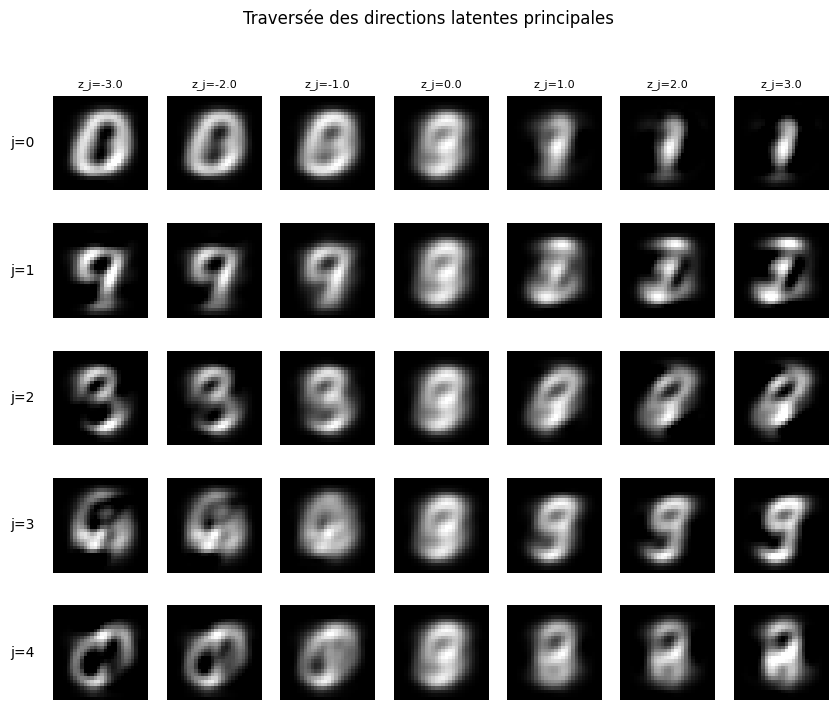

In [2]:
# TP Modèles génératifs - Partie 2 : modèle gaussien pour des images
# Chaque bloc "# %%" = une cellule de notebook

# %% Imports
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

# %% 2.1 - Chargement des images (MNIST, sinon chiffres sklearn 8x8 hors-ligne)
try:
    from sklearn.datasets import fetch_openml
    mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
    data = mnist.data.astype(np.float64) / 255.0
    side = 28
except Exception as e:
    print("MNIST indisponible, utilisation de load_digits (8x8). Raison :", e)
    from sklearn.datasets import load_digits
    data = load_digits().data / 16.0
    side = 8

N = min(5000, len(data))
idx = np.random.choice(len(data), N, replace=False)
X = data[idx]                      # (N, d)
d = X.shape[1]
print("X :", X.shape)

# %% Moyenne et covariance empiriques
mu_hat = X.mean(axis=0)
Xc = X - mu_hat
Sigma_hat = Xc.T @ Xc / N

plt.imshow(mu_hat.reshape(side, side), cmap='gray')
plt.title("Image moyenne"); plt.axis('off'); plt.show()

# %% Décomposition spectrale (ACP) + eigen-images
eigvals, E = np.linalg.eigh(Sigma_hat)
order = np.argsort(eigvals)[::-1]
eigvals = np.clip(eigvals[order], 0, None)     # évite de petites valeurs négatives numériques
E = E[:, order]

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for j, ax in enumerate(axes.ravel()):
    ax.imshow(E[:, j].reshape(side, side), cmap='gray')
    ax.set_title(f"λ={eigvals[j]:.2f}", fontsize=8); ax.axis('off')
plt.suptitle("Premières eigen-images"); plt.show()

plt.plot(np.cumsum(eigvals) / eigvals.sum())
plt.xlabel("nb de composantes"); plt.ylabel("variance expliquée cumulée"); plt.show()

# %% Génération : x = mu + E_r Λ_r^{1/2} z, z ~ N(0, I_r)
def generate(r, n=10):
    z = np.random.randn(n, r)
    return mu_hat + z @ (E[:, :r] * np.sqrt(eigvals[:r])).T   # (n, d)

rs = [r for r in (10, 25, 50) if r <= d]
fig, axes = plt.subplots(len(rs), 10, figsize=(14, 1.6 * len(rs)))
axes = np.atleast_2d(axes)
for row, r in enumerate(rs):
    imgs = generate(r)
    for col in range(10):
        axes[row, col].imshow(np.clip(imgs[col], 0, 1).reshape(side, side), cmap='gray')
        axes[row, col].axis('off')
    axes[row, 0].set_title(f"r = {r}", fontsize=9, loc='left')
plt.show()

# Discussion : images floues, "fantomatiques" ; un gaussien ne capture que moyenne + corrélations d'ordre 2.

# %% 2.2 - Générateur affine G(z) = mu + A z, avec A = E_r Λ_r^{1/2}
r = min(25, d)
A = E[:, :r] * np.sqrt(eigvals[:r])       # (d, r)
G = lambda z: mu_hat + A @ z
# Vérification : même loi que le modèle précédent
z = np.random.randn(r)
assert np.allclose(G(z), mu_hat + E[:, :r] @ (np.sqrt(eigvals[:r]) * z))
# Covariance de G(z) = A A^T = E_r Λ_r E_r^T (approximation de rang r de Sigma_hat)

# %% Variation d'une coordonnée latente à la fois (les autres à 0)
vals = np.linspace(-3, 3, 7)
n_dir = 5
fig, axes = plt.subplots(n_dir, len(vals), figsize=(10, 1.6 * n_dir))
for j in range(n_dir):
    for c, v in enumerate(vals):
        z = np.zeros(r); z[j] = v
        axes[j, c].imshow(np.clip(G(z), 0, 1).reshape(side, side), cmap='gray')
        axes[j, c].axis('off')
        if j == 0:
            axes[j, c].set_title(f"z_j={v:.1f}", fontsize=8)
    axes[j, 0].text(-0.2, 0.5, f"j={j}", transform=axes[j, 0].transAxes, ha='right', va='center')
plt.suptitle("Traversée des directions latentes principales"); plt.show()

# Interprétation : les plus grandes valeurs propres = variations dominantes (épaisseur, inclinaison, 0 vs 1...).
# Limite : G est affine, donc toute interpolation est linéaire (mélange d'images fantômes), pas de structure non linéaire.

In [3]:
# TP Modèles génératifs - Partie 3 : modèles autorégressifs
# Chaque bloc "# %%" = une cellule de notebook

# %% Imports
import re
import numpy as np
from collections import Counter, defaultdict

np.random.seed(0)

# =====================================================================
# 3.1 CHAÎNE DE MARKOV SUR DU TEXTE
# =====================================================================
# %% Corpus + tokenisation
texte = """
Une souris verte courait dans l'herbe. Une souris grise dormait dans la maison.
Une maison blanche se trouvait près de la rivière. Le chat noir regardait la souris verte.
Le chat dormait dans la maison. La souris courait dans la rivière. Une rivière traversait l'herbe.
Le chat noir courait dans l'herbe. Une souris blanche regardait le chat gris.
Le chat gris dormait près de la rivière. La maison grise se trouvait dans l'herbe.
"""

# Option nltk : import nltk; nltk.download('punkt'); nltk.download('punkt_tab')
#               tokens = nltk.word_tokenize(texte, language='french')
tokens = re.findall(r"\w+'?|[.,;!?]", texte)
print(len(tokens), "tokens :", tokens[:15])

# %% Vocabulaire
vocab = sorted(set(tokens))
word2idx = {w: i for i, w in enumerate(vocab)}
print("Mots uniques :", len(vocab))

# %% Paires, matrice de transition creuse (dictionnaire de dictionnaires)
def make_pairs(corpus):
    return list(zip(corpus[:-1], corpus[1:]))

def build_transition_matrix(corpus):
    d = defaultdict(lambda: defaultdict(int))
    for w1, w2 in make_pairs(corpus):
        d[w1][w2] += 1
    return d

T = build_transition_matrix(tokens)

# Dictionnaire plutôt que matrice dense : |V|^2 cases dont l'immense majorité vaut 0
# (pour |V| = 50 000, une matrice dense = 2,5 milliards de cases) ; le dico ne stocke que les paires vues.
print(f"Cases d'une matrice dense : {len(vocab)**2} | paires réellement observées : {sum(len(v) for v in T.values())}")

# %% 10 bigrammes les plus fréquents
for pair, c in Counter(make_pairs(tokens)).most_common(10):
    print(pair, c)

# %% Échantillonnage du mot suivant + génération
def sample_next_word(word, transition_matrix):
    nxt = transition_matrix[word]
    words = list(nxt.keys())
    counts = np.array(list(nxt.values()), dtype=float)
    return np.random.choice(words, p=counts / counts.sum())

def generate_sentence(start, transition_matrix, max_len=30):
    sent = [start]
    while sent[-1] != '.' and len(sent) < max_len:
        if sent[-1] not in transition_matrix:     # mot sans successeur
            break
        sent.append(sample_next_word(sent[-1], transition_matrix))
    return " ".join(sent)

for _ in range(5):
    print(generate_sentence("Une", T))

# %% Approfondissement : ordre 2 (tri-grammes)
def build_transition_matrix_order2(corpus):
    d = defaultdict(lambda: defaultdict(int))
    for w1, w2, w3 in zip(corpus[:-2], corpus[1:-1], corpus[2:]):
        d[(w1, w2)][w3] += 1
    return d

T2 = build_transition_matrix_order2(tokens)

def generate_sentence_order2(start, transition_matrix1, transition_matrix2, max_len=30):
    sent = [start, sample_next_word(start, transition_matrix1)]
    while sent[-1] != '.' and len(sent) < max_len:
        ctx = (sent[-2], sent[-1])
        if ctx not in transition_matrix2:
            break
        sent.append(sample_next_word(ctx, transition_matrix2))
    return " ".join(sent)

for _ in range(5):
    print(generate_sentence_order2("Une", T, T2))

# =====================================================================
# 3.2 / 3.3 MODÈLE AUTORÉGRESSIF CATÉGORIEL (ordre n, lissage de Laplace)
# =====================================================================
# %% Corpus jouet
BOS, EOS = "<bos>", "<eos>"
V = ["A", "B", "C", "D", EOS]                 # tokens pouvant être prédits
corpus = [
    ["A", "B", "C", EOS],
    ["A", "B", "D", EOS],
    ["A", "C", "D", EOS],
    ["B", "C", "D", EOS],
]

# Factorisation (longueur 4) :
# p(x1,x2,x3,x4) = p(x1|<bos>) p(x2|x1) p(x3|x2) p(x4|x3)   (ordre 1)

# %% Modèle générique d'ordre n
class NgramModel:
    def __init__(self, order=1, alpha=0.0):
        self.order, self.alpha = order, alpha
        self.counts = defaultdict(Counter)

    def fit(self, corpus):
        for seq in corpus:
            padded = [BOS] * self.order + seq
            for t in range(self.order, len(padded)):
                ctx = tuple(padded[t - self.order:t])
                self.counts[ctx][padded[t]] += 1
        return self

    def probs(self, ctx):
        c = self.counts.get(ctx, Counter())
        raw = np.array([c[v] + self.alpha for v in V], dtype=float)
        if raw.sum() == 0:                      # contexte jamais vu et pas de lissage
            return np.ones(len(V)) / len(V)
        return raw / raw.sum()

    def nll(self, corpus):
        total, n = 0.0, 0
        for seq in corpus:
            padded = [BOS] * self.order + seq
            for t in range(self.order, len(padded)):
                ctx = tuple(padded[t - self.order:t])
                p = self.probs(ctx)[V.index(padded[t])]
                total += -np.log(p) if p > 0 else np.inf
                n += 1
        return total / n

    def sample(self, max_len=10):
        seq = [BOS] * self.order
        while len(seq) - self.order < max_len:
            ctx = tuple(seq[-self.order:])
            tok = np.random.choice(V, p=self.probs(ctx))
            seq.append(tok)
            if tok == EOS:
                break
        return seq[self.order:]

    def n_params(self):
        """Paramètres effectivement stockés (contextes vus x successeurs vus)."""
        return sum(len(c) for c in self.counts.values())

# %% 3.2 Ordre 1 : sans / avec lissage
m1_raw = NgramModel(order=1, alpha=0.0).fit(corpus)
m1_lap = NgramModel(order=1, alpha=1.0).fit(corpus)
print("NLL moyenne ordre 1 sans lissage :", round(m1_raw.nll(corpus), 4))
print("NLL moyenne ordre 1 Laplace      :", round(m1_lap.nll(corpus), 4))

for name, m in [("sans lissage", m1_raw), ("Laplace", m1_lap)]:
    seqs = [" ".join(m.sample()) for _ in range(20)]
    print(f"\n--- {name} ({len(set(seqs))} séquences distinctes sur 20) ---")
    for s in seqs[:20]:
        print(s)

# %% 3.3 Ordre 2 et comparaison
m2_raw = NgramModel(order=2, alpha=0.0).fit(corpus)
m2_lap = NgramModel(order=2, alpha=1.0).fit(corpus)

print("NLL ordre 2 sans lissage :", round(m2_raw.nll(corpus), 4))
print("NLL ordre 2 Laplace      :", round(m2_lap.nll(corpus), 4))
print("Paramètres non nuls  ordre 1 :", m1_raw.n_params(), "| ordre 2 :", m2_raw.n_params())
print(f"Paramètres théoriques ordre 1 : {(len(V)+1)*len(V)} | ordre 2 : {(len(V)+1)**2 * len(V)}")

seqs2 = [" ".join(m2_raw.sample()) for _ in range(20)]
print("\nOrdre 2 sans lissage :", set(seqs2))
seqs1 = [" ".join(m1_raw.sample()) for _ in range(200)]
print("Ordre 1 sans lissage (200 tirages) :", set(seqs1))

# Discussion : l'ordre 2 colle davantage au corpus (NLL plus basse, séquences quasi recopiées),
# mais le nombre de paramètres explose en |V|^3 et la majorité des contextes sont rares ou jamais vus
# => surapprentissage si le corpus est petit. Le lissage redistribue de la masse aux transitions non vues.

88 tokens : ['Une', 'souris', 'verte', 'courait', 'dans', "l'", 'herbe', '.', 'Une', 'souris', 'grise', 'dormait', 'dans', 'la', 'maison']
Mots uniques : 26
Cases d'une matrice dense : 676 | paires réellement observées : 50
("l'", 'herbe') 4
('herbe', '.') 4
('.', 'Une') 4
('.', 'Le') 4
('Le', 'chat') 4
('Une', 'souris') 3
('courait', 'dans') 3
('dans', "l'") 3
('dans', 'la') 3
('la', 'rivière') 3
Une souris courait dans la rivière .
Une souris blanche regardait la rivière .
Une souris blanche se trouvait près de la souris blanche regardait la rivière .
Une maison .
Une rivière .
Une souris verte .
Une souris grise dormait dans la maison .
Une maison blanche se trouvait près de la rivière .
Une souris grise dormait dans la maison .
Une souris grise dormait dans la maison .
NLL moyenne ordre 1 sans lissage : 0.4986
NLL moyenne ordre 1 Laplace      : 1.0038

--- sans lissage (6 séquences distinctes sur 20) ---
A B C D <eos>
A C D <eos>
A C D <eos>
A B C D <eos>
A B C <eos>
A B C D <eos>
